# Trabajo Práctico 3: Clasificación de imágenes satelitales

In [1]:
import csv
import json
import random
import time
import copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


In [2]:
#semilla
SEED = 22
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [3]:
#Dispositivo
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')


In [4]:
#Directorios
DATA_DIR = Path('EuroSAT')


In [ ]:
#Hiperparametros
BATCH_SIZE = 64
EPOCHS = 30
LR = 1e-3
GRAD_EPOCHS = 3
NUM_WORKERS = 0
torch.set_num_threads(8) 

## Carga de datos

In [6]:
#Lectura JSON
with (DATA_DIR / 'label_map.json').open(encoding='utf-8') as f:
    class_to_idx = json.load(f)

# Ordenamos los nombres por su etiqueta numérica (0 a 9).
class_names = []
for label in range(10):
    for name in class_to_idx:
        if class_to_idx[name] == label:
            class_names.append(name)
assert len(class_names) == 10
num_classes = len(class_names)


In [7]:
# Adaptación a EuroSAT: los CSV ya indican qué imágenes van en cada partición.
# Solo leemos rutas y etiquetas; todavía no abrimos las imágenes.
def leer_split(nombre):
    muestras = []
    rutas_vistas = set()
    with (DATA_DIR / nombre).open(encoding='utf-8-sig', newline='') as f:
        reader = csv.DictReader(f)
        for row in reader:
            ruta = row['Filename'].replace('\\', '/')
            label = int(row['Label'])
            assert label == class_to_idx[row['ClassName']]
            assert (DATA_DIR / ruta).is_file(), ruta
            assert ruta not in rutas_vistas, 'Archivos repetidos'
            rutas_vistas.add(ruta)
            muestras.append((ruta, label))
    assert len(muestras) > 0
    return muestras


In [8]:
#Lectura de CSV's
train_samples = leer_split('train.csv')
val_samples = leer_split('validation.csv')
test_samples = leer_split('test.csv')

splits = {'train': train_samples, 'val': val_samples, 'test': test_samples}

In [9]:
from IPython.display import display, Markdown

tabla = '| Clase | Train | Val | Test |\n'
tabla += '|---|---:|---:|---:|\n'

for label in range(num_classes):
    counts = []
    for samples in [train_samples, val_samples, test_samples]:
        count = 0
        for ruta, image_label in samples:
            if image_label == label:
                count += 1
        assert count > 0
        counts.append(count)
    tabla += f'| {class_names[label]} | {counts[0]} | {counts[1]} | {counts[2]} |\n'

tabla += f'| **Total** | **{len(train_samples)}** | **{len(val_samples)}** | **{len(test_samples)}** |\n'
display(Markdown(tabla))


| Clase | Train | Val | Test |
|---|---:|---:|---:|
| AnnualCrop | 2100 | 600 | 300 |
| Forest | 2100 | 600 | 300 |
| HerbaceousVegetation | 2100 | 600 | 300 |
| Highway | 1750 | 500 | 250 |
| Industrial | 1750 | 500 | 250 |
| Pasture | 1400 | 400 | 200 |
| PermanentCrop | 1750 | 500 | 250 |
| Residential | 2100 | 600 | 300 |
| River | 1750 | 500 | 250 |
| SeaLake | 2100 | 600 | 300 |
| **Total** | **18900** | **5400** | **2700** |


## Preprocesamiento de datos
Ambos modelos usan imágenes de 64 × 64, los mismos aumentos geométricos y la misma
normalización de ImageNet. Estos valores fijos no se estiman con test.
En entrenamiento aplicamos reflejos y giros; en evaluación no hay cambios aleatorios.
La resolución coincide con el dataset nativo. No es la resolución original de
preentrenamiento de ResNet18 y eso limita la comparación con resultados de otros trabajos.


In [ ]:
#Data augmentation: Rotar 
# Elegimos 0, 90, 180 o 270 grados; no cambiamos la clase del terreno.
def rotacion90(img):
    vueltas = random.randrange(4)
    return img.rotate(90 * vueltas)

In [11]:
#Transformación a tensores
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.Lambda(rotacion90),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


In [12]:
# ImageFolder abre los archivos por demanda y asigna la clase según la carpeta.
train_full = datasets.ImageFolder(DATA_DIR, transform=train_transform)
eval_full = datasets.ImageFolder(DATA_DIR, transform=eval_transform)
assert train_full.class_to_idx == class_to_idx

# Adaptación a los CSV de EuroSAT: relacionamos cada ruta con su posición
# en ImageFolder, para conservar las particiones existentes con Subset.
indice_por_ruta = {}
for index in range(len(train_full.samples)):
    ruta, label = train_full.samples[index]
    ruta_relativa = Path(ruta).relative_to(DATA_DIR).as_posix()
    indice_por_ruta[ruta_relativa] = index

def obtener_indices(samples):
    indices = []
    for ruta, label in samples:
        index = indice_por_ruta[ruta]
        assert train_full.samples[index][1] == label
        indices.append(index)
    return indices


In [13]:
# Subset selecciona índices de un Dataset
train_indices = obtener_indices(train_samples)
val_indices = obtener_indices(val_samples)
test_indices = obtener_indices(test_samples)

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(eval_full, val_indices)
test_dataset = Subset(eval_full, test_indices)


In [14]:
# MINI-BATCHES: agrupamos imágenes; en entrenamiento mezclamos su orden.
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)


### CNN propia
Usamos cuatro bloques Conv-BatchNorm-LeakyReLU-MaxPool, con 16, 32, 64 y 128 canales.
El pooling global produce 128 características. Dropout regulariza el clasificador.
La arquitectura se conserva y todos sus pesos se entrenan desde cero con Adam y
learning rate fijo.


In [ ]:
# Clase para registrar los pesos y definir el forward
class MiCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # Convolucion y BatchNorm: estabiliza las activaciones internas.
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1, bias=False)  
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 128, 3, padding=1, bias=False)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2)
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.3)  # Apaga el 30% durante entrenamiento.
        self.classifier = nn.Linear(128, num_classes)

    def forward_features(self, x):
        # Forward propagation: cuatro bloques convolucionales.
        x = self.conv1(x)
        x = self.bn1(x)
        x = F.leaky_relu(x)  # Función de activación
        x = self.pool(x)  # Max pooling
        x = self.conv2(x)
        x = self.bn2(x)
        x = F.leaky_relu(x)
        x = self.pool(x)
        x = self.conv3(x)
        x = self.bn3(x)
        x = F.leaky_relu(x)
        x = self.pool(x)
        x = self.conv4(x)
        x = self.bn4(x)
        x = F.leaky_relu(x)
        x = self.pool(x)
        x = self.global_pool(x)
        return torch.flatten(x, 1)  

    def forward(self, x):
        x = self.forward_features(x)
        x = self.dropout(x)
        return self.classifier(x)  


In [16]:
model = MiCNN(num_classes).to(device)
print(model)
parametros_entrenables = 0
for parameter in model.parameters():
    if parameter.requires_grad:
        parametros_entrenables += parameter.numel()
print('Parámetros entrenables:', parametros_entrenables)


MiCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (global_pool): AdaptiveAvgPool2d(output_size=1)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=10, b

### Entrenamiento y flujo de gradientes
Registramos loss y accuracy en entrenamiento y validación. Elegimos los pesos
de la época con menor pérdida de validación.
Durante las primeras tres épocas monitoreamos la norma L2 de los gradientes por
capa. El gráfico permite observar si las capas reciben señal y comparar su evolución.


In [ ]:
criterion = nn.CrossEntropyLoss()

def entrenar_una_epoca(model, loader, criterion, optimizer, monitorear=False):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    registros = {}
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)  # Forward propagation
        loss = criterion(logits, labels)  # Loss
        if not torch.isfinite(loss).item():
            raise RuntimeError('Pérdida no finita')
        loss.backward()  # Backpropagation
        if monitorear:
            for name, parameter in model.named_parameters():
                if parameter.grad is None:
                    continue
                grad = parameter.grad.detach()
                norma = grad.norm().item()
                if not np.isfinite(norma):
                    raise RuntimeError('Gradiente no finito en ' + name)
                if parameter.ndim > 1:
                    if name not in registros:
                        registros[name] = []
                    registros[name].append(norma)
        optimizer.step()  
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total, registros

def evaluar(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100 * correct / total


In [18]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
model = MiCNN(num_classes).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'seconds': []}
gradient_history = []
best_val_loss = float('inf')
best_epoch = 0
best_val_acc = 0.0
for epoch in range(1, EPOCHS + 1):
    inicio = time.time()
    train_loss, train_acc, registros = entrenar_una_epoca(
        model, train_loader, criterion, optimizer, monitorear=epoch <= GRAD_EPOCHS)
    val_loss, val_acc = evaluar(model, val_loader, criterion)
    seconds = time.time() - inicio
    for key, value in [('train_loss', train_loss), ('val_loss', val_loss),
                       ('train_acc', train_acc), ('val_acc', val_acc), ('seconds', seconds)]:
        history[key].append(value)
    if registros:
        gradient_history.append({'epoch': epoch, 'capas': registros})
    print(f'Época {epoch}/{EPOCHS} | train {train_loss:.4f}, {train_acc:.2f}% '
          f'| val {val_loss:.4f}, {val_acc:.2f}% | {seconds:.1f} s', flush=True)
    if val_loss < best_val_loss:
        best_val_loss, best_val_acc, best_epoch = val_loss, val_acc, epoch
        best_weights = copy.deepcopy(model.state_dict())
model.load_state_dict(best_weights)
model.eval()
tabla_mejor = '| Época elegida | Accuracy de validación (%) |\n'
tabla_mejor += '|---:|---:|\n'
tabla_mejor += f'| {best_epoch} | {best_val_acc:.2f} |\n'
display(Markdown(tabla_mejor))


Época 1/30 | train 0.9109, 68.13% | val 0.8419, 70.72% | 73.5 s
Época 2/30 | train 0.6563, 76.87% | val 0.5814, 80.72% | 61.4 s
Época 3/30 | train 0.5468, 80.87% | val 0.5064, 81.04% | 75.9 s
Época 4/30 | train 0.4969, 82.90% | val 0.4231, 84.65% | 60.7 s
Época 5/30 | train 0.4309, 85.06% | val 0.3845, 86.39% | 55.1 s
Época 6/30 | train 0.3970, 86.37% | val 0.4071, 85.65% | 56.3 s
Época 7/30 | train 0.3646, 87.62% | val 0.5511, 81.07% | 51.6 s
Época 8/30 | train 0.3440, 88.29% | val 0.3090, 88.81% | 51.5 s
Época 9/30 | train 0.3250, 88.99% | val 0.3140, 88.74% | 56.2 s
Época 10/30 | train 0.3173, 89.12% | val 0.2465, 91.72% | 49.5 s
Época 11/30 | train 0.3021, 89.69% | val 0.2479, 91.44% | 54.1 s
Época 12/30 | train 0.2954, 89.92% | val 0.4067, 85.98% | 54.3 s
Época 13/30 | train 0.2807, 90.42% | val 0.3728, 86.59% | 58.4 s
Época 14/30 | train 0.2655, 90.85% | val 0.2743, 90.04% | 53.8 s
Época 15/30 | train 0.2618, 90.94% | val 0.8423, 78.24% | 64.0 s
Época 16/30 | train 0.2671, 90.81%

| Época elegida | Accuracy de validación (%) |
|---:|---:|
| 26 | 93.37 |


### Curvas de Aprendizaje: pérdida y accuracy en entrenamiento y validación.

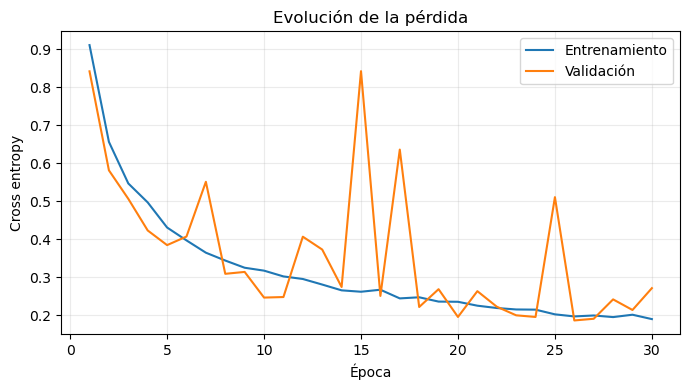

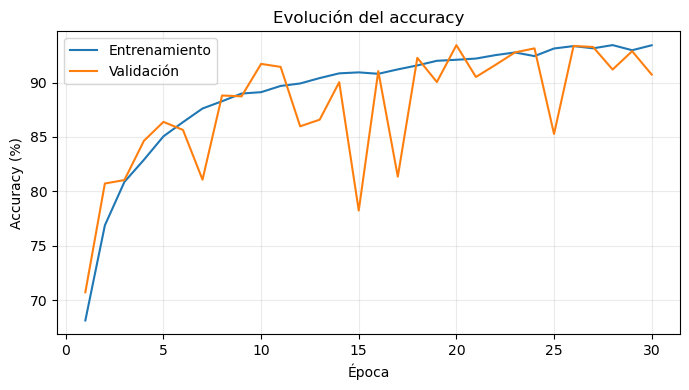

In [ ]:

epochs = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, history['train_loss'], label='Entrenamiento')
plt.plot(epochs, history['val_loss'], label='Validación')
plt.xlabel('Época')
plt.ylabel('Cross entropy')
plt.title('Evolución de la pérdida')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs, history['train_acc'], label='Entrenamiento')
plt.plot(epochs, history['val_acc'], label='Validación')
plt.xlabel('Época')
plt.ylabel('Accuracy (%)')
plt.title('Evolución del accuracy')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


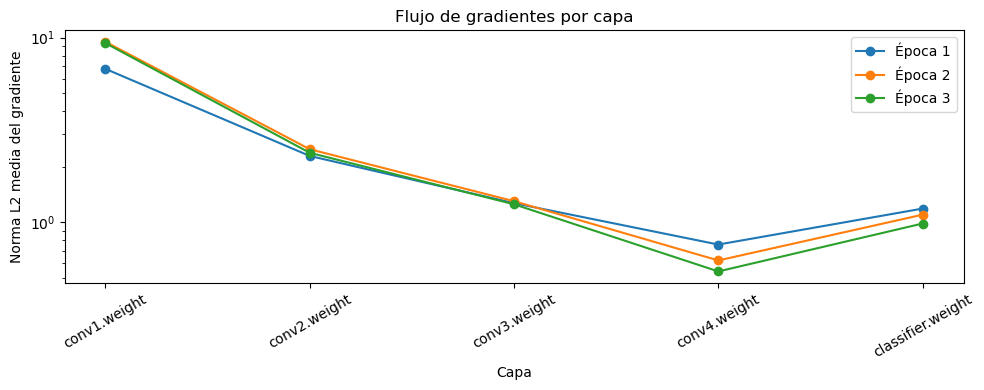

In [20]:
plt.figure(figsize=(10, 4))
for record in gradient_history:
    names = list(record['capas'])
    normas = []
    for name in names:
        normas.append(np.mean(record['capas'][name]))
    plt.plot(names, normas, marker='o', label='Época ' + str(record['epoch']))
plt.yscale('log')
plt.xlabel('Capa')
plt.ylabel('Norma L2 media del gradiente')
plt.title('Flujo de gradientes por capa')
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()


### Resultados de la CNN y evolución del entrenamiento

La CNN tiene 98.970 parámetros entrenables. Las convoluciones extraen las
características y el pooling global las resume antes del clasificador.

En 30 épocas con Adam y LR fijo de 0,001, train pasó de 68,13% a 93,43%.
La mejor época por pérdida de validación fue la 26, con loss 0,1863 y
accuracy 93,37%. La última época terminó con 90,74% en validación, por lo
que conservar los últimos pesos habría descartado un estado mejor.

La pérdida de entrenamiento disminuyó de 0,9109 a 0,1898, pero validación no
mejoró de manera uniforme. La corrida muestra aprendizaje, junto con una variabilidad importante
de validación. No corresponde
atribuir toda esa variación a sobreajuste ni afirmar subajuste solo por el número
de convoluciones. Además, train incluye aumentos y dropout, mientras que validación no.

El estado seleccionado obtuvo en las 2.700 imágenes de test un accuracy de
94,70%. Residential tuvo recall de 1,00 al redondear
a dos decimales, mientras que HerbaceousVegetation presentó el menor recall,
0,86. Por lo tanto, el rendimiento global alto no elimina dificultades
particulares en las coberturas vegetales.

### Flujo de gradientes

Las primeras tres épocas mantienen gradientes finitos en las capas monitoreadas,
mientras la pérdida de entrenamiento disminuye. No observamos evidencia clara
de desvanecimiento o explosión durante ese período.
La norma absoluta depende de la escala y de la cantidad de parámetros: una capa
con menor norma no demuestra por sí sola desvanecimiento. El monitoreo se limita
a las primeras épocas, por lo que no permite afirmar qué ocurrió después.


## 2. Análisis de errores y espacio latente
### Evaluación en test
Evaluamos la CNN con los pesos seleccionados por validación. Reportamos accuracy
y precision, recall y F1 por clase.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from IPython.display import display, Markdown
from torchvision import models

cnn_custom = model  
history_custom = copy.deepcopy(history)
best_epoch_custom = best_epoch
best_val_acc_custom = best_val_acc

def predecir(modelo, loader):
    modelo.eval()
    reales = []
    predichas = []
    with torch.no_grad():  
        for images, labels in loader:
            images = images.to(device)
            logits = modelo(images)
            _, predicted = torch.max(logits, 1)
            reales.extend(labels.tolist())
            predichas.extend(predicted.cpu().tolist())
    return np.array(reales), np.array(predichas)

y_test, pred_custom = predecir(cnn_custom, test_loader)
acc_custom = accuracy_score(y_test, pred_custom)
print('Accuracy test:', round(acc_custom, 4))

def mostrar_metricas(reales, predichas):
    reporte = classification_report(reales, predichas, labels=range(num_classes),
                                    target_names=class_names, zero_division=0, output_dict=True)
    tabla_metricas = '| Clase | Precision | Recall | F1 | Imágenes |\n'
    tabla_metricas += '|---|---:|---:|---:|---:|\n'
    for name in class_names:
        fila = reporte[name]
        tabla_metricas += (f'| {name} | {fila["precision"]:.2f} | {fila["recall"]:.2f} | '
                           f'{fila["f1-score"]:.2f} | {int(fila["support"])} |\n')
    display(Markdown(tabla_metricas))

mostrar_metricas(y_test, pred_custom)


Accuracy test: 0.947


| Clase | Precision | Recall | F1 | Imágenes |
|---|---:|---:|---:|---:|
| AnnualCrop | 0.97 | 0.92 | 0.95 | 300 |
| Forest | 0.99 | 0.97 | 0.98 | 300 |
| HerbaceousVegetation | 0.96 | 0.86 | 0.90 | 300 |
| Highway | 0.95 | 0.93 | 0.94 | 250 |
| Industrial | 0.98 | 0.96 | 0.97 | 250 |
| Pasture | 0.88 | 0.95 | 0.92 | 200 |
| PermanentCrop | 0.87 | 0.96 | 0.91 | 250 |
| Residential | 0.97 | 1.00 | 0.98 | 300 |
| River | 0.90 | 0.94 | 0.92 | 250 |
| SeaLake | 0.98 | 0.99 | 0.98 | 300 |


### Matriz de confusión

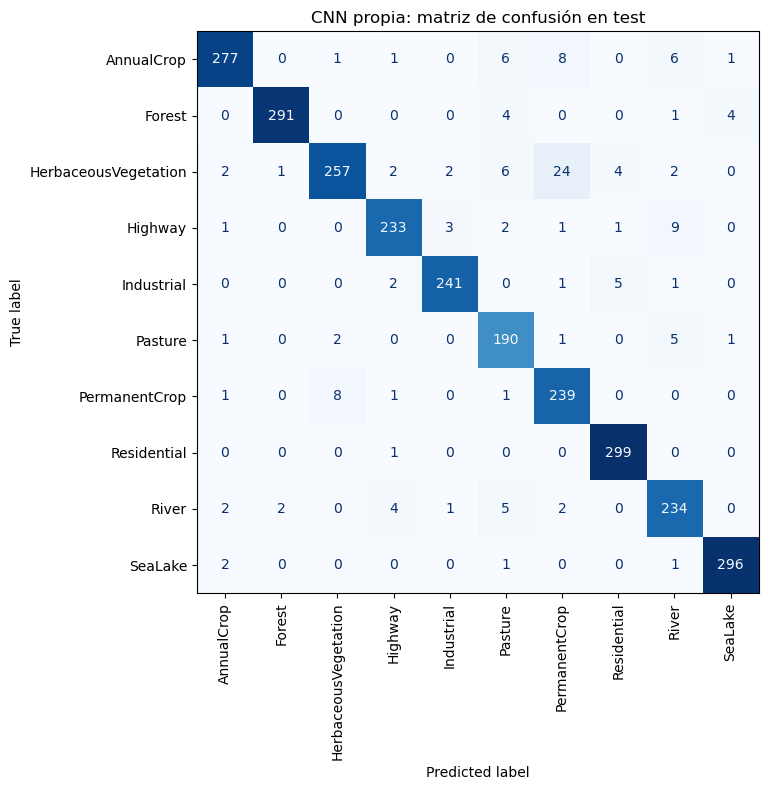

In [22]:
cm_custom = confusion_matrix(y_test, pred_custom, labels=range(num_classes))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm_custom, display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False, xticks_rotation=90
)
ax.set_title('CNN propia: matriz de confusión en test')
plt.tight_layout()
plt.show()


### Confusiones más frecuentes

In [23]:
# Agrupamos ambos sentidos de cada confusión.
pares = []
for a in range(num_classes):
    for b in range(a + 1, num_classes):
        cantidad = int(cm_custom[a, b] + cm_custom[b, a])
        if cantidad > 0:
            pares.append((cantidad, a, b))
pares.sort(reverse=True)
tabla_pares = '| Clase A | Clase B | Total | A → B | B → A |\n'
tabla_pares += '|---|---|---:|---:|---:|\n'
for cantidad, a, b in pares[:5]:
    tabla_pares += (f'| {class_names[a]} | {class_names[b]} | {cantidad} | '
                    f'{cm_custom[a, b]} | {cm_custom[b, a]} |\n')
display(Markdown(tabla_pares))


| Clase A | Clase B | Total | A → B | B → A |
|---|---|---:|---:|---:|
| HerbaceousVegetation | PermanentCrop | 32 | 24 | 8 |
| Highway | River | 13 | 9 | 4 |
| Pasture | River | 10 | 5 | 5 |
| AnnualCrop | PermanentCrop | 9 | 8 | 1 |
| HerbaceousVegetation | Pasture | 8 | 6 | 2 |


### Análisis de los errores


El par más confundido fue HerbaceousVegetation ↔ PermanentCrop, con 32 errores:
24 de HerbaceousVegetation hacia PermanentCrop y ocho en sentido contrario.
Al revisar recortes mal clasificados de HerbaceousVegetation se observan manchas de vegetación y suelo
separadas por caminos; no hay filas de cultivo nítidas. Uno de los recortes de
PermanentCrop es una superficie verde bastante homogénea y otro muestra una trama
de plantación que se ve tenue a esta resolución. La distinción exige reconocer
la organización espacial, además del color. Esto justifica la similitud visual
del par, sin probar qué característica causó cada decisión interna de la red.

Highway ↔ River sumó 13 errores: nueve carreteras predichas como río y cuatro
ríos predichos como carretera. Dos recortes revisados de Highway contienen
trazos estrechos y cruces sobre fondos oscuros o verdes. Comparten el carácter
lineal con los ríos, pero los cruces y la regularidad de los caminos son diferencias
que el modelo no aprovechó en esos casos. Los recortes tienen solo 64 × 64 píxeles,
por lo que esas diferencias ocupan pocos píxeles.

También aparecen Pasture ↔ River con diez errores, AnnualCrop ↔ PermanentCrop
con nueve y HerbaceousVegetation ↔ Pasture con ocho. Los conteos por sí solos
no permiten asignar una explicación visual a todos ellos: el análisis detallado
anterior se basa en la revisión de recortes de los dos primeros pares.


### Espacio latente: PCA y t-SNE
Extraemos las 128 características anteriores al clasificador. PCA se ajusta con
train y proyecta test. t-SNE representa una muestra reproducible de test, con las
etiquetas usadas solo para colorear. Ambos métodos están incluidos en el enunciado.
PCA permite conocer cuánta varianza conserva la proyección. Los ejes y distancias
globales de t-SNE no tienen una interpretación métrica fiable. La lectura visual
debe contrastarse con las confusiones observadas, sin presentarla como prueba de
clusters naturales. 


In [ ]:
def extraer_features(modelo, loader):
    modelo.eval()
    features = []
    etiquetas = []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            salida = modelo.forward_features(images)  # Antes del clasificador.
            features.append(salida.cpu().numpy())
            etiquetas.extend(labels.tolist())
    return np.concatenate(features, axis=0), np.array(etiquetas)

train_latente_dataset = Subset(eval_full, train_indices)
train_latente_loader = DataLoader(train_latente_dataset, batch_size=BATCH_SIZE,
                                  shuffle=False, num_workers=NUM_WORKERS)
features_train, labels_latentes_train = extraer_features(cnn_custom, train_latente_loader)
features_test, labels_latentes_test = extraer_features(cnn_custom, test_loader)

pca = PCA(n_components=2, svd_solver='full')
pca.fit(features_train)  # Sin utilizar test para ajustar la proyección.
proyeccion_test = pca.transform(features_test)
varianza_pca = pca.explained_variance_ratio_.sum()

plt.figure(figsize=(10, 7))
for label in range(num_classes):
    seleccion = labels_latentes_test == label
    plt.scatter(proyeccion_test[seleccion, 0], proyeccion_test[seleccion, 1],
                s=12, alpha=0.5, label=class_names[label])
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.title('Espacio latente de la CNN propia: test')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
display(Markdown(f'Las dos componentes conservan {varianza_pca:.1%} de la '
                 'varianza de las características de entrenamiento. '
                 'Para interpretar los grupos debemos considerar esa pérdida de información.'))


NameError: name 'Subset' is not defined

Las dos componentes conservan varianza_pca: 0.1% de la varianza de las características de entrenamiento. Para interpretar los grupos debemos considerar esa pérdida de información.

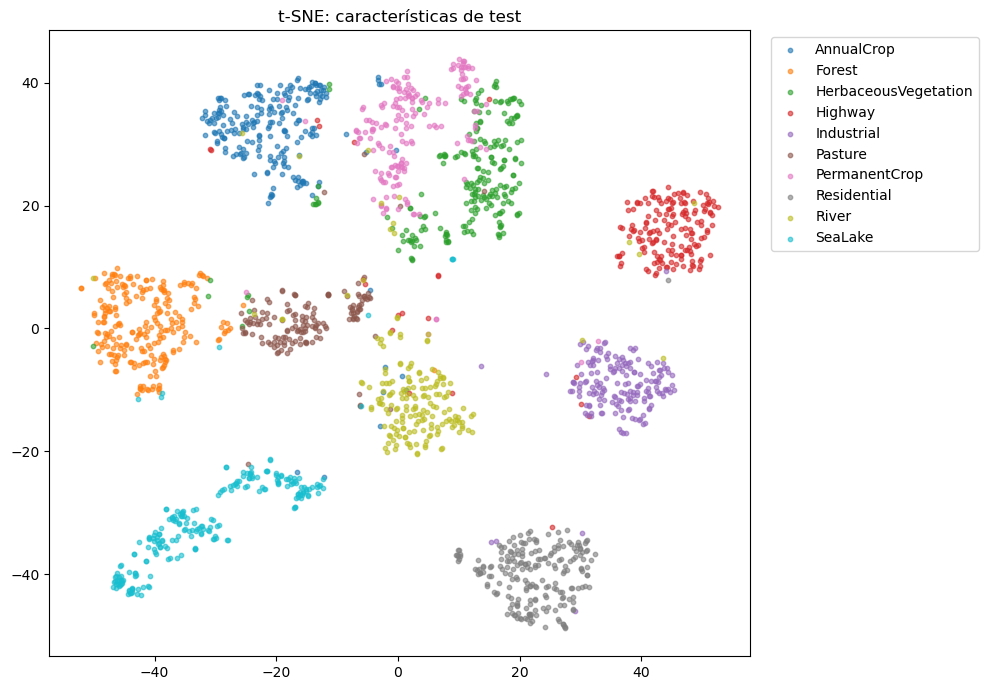

In [25]:
from sklearn.manifold import TSNE
muestreo = np.random.default_rng(SEED)
indices_latentes = muestreo.choice(len(features_test), min(2000, len(features_test)), replace=False)
features_muestra = features_test[indices_latentes]
labels_muestra = labels_latentes_test[indices_latentes]
tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED)
proyeccion_tsne = tsne.fit_transform(features_muestra)
plt.figure(figsize=(10, 7))
for label in range(num_classes):
    seleccion = labels_muestra == label
    plt.scatter(proyeccion_tsne[seleccion, 0], proyeccion_tsne[seleccion, 1],
                s=10, alpha=0.6, label=class_names[label])
plt.title('t-SNE: características de test')
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


### Análisis del espacio latente


PCA conserva 45,7% de la varianza de train con dos componentes. Se distinguen
regiones dominadas por Forest y SeaLake hacia la izquierda, AnnualCrop en la parte
superior y Residential e Industrial hacia la derecha. HerbaceousVegetation,
PermanentCrop y Pasture se mezclan en la zona central. La superposición no demuestra
que las clases sean inseparables en las 128 dimensiones: la proyección descarta
el 54,3% de la varianza.

En la proyección t-SNE de 2.000 imágenes aparecen grupos mayormente dominados por
una clase, especialmente Residential, Industrial y Highway. HerbaceousVegetation
y PermanentCrop quedan próximas y muestran puntos mezclados, en consonancia con
la confusión principal del clasificador. SeaLake forma más de una nube, por lo
que ni siquiera una misma clase tiene que aparecer como un único grupo compacto.

Estas visualizaciones muestran que la representación aprendida contiene información
útil para distinguir las clases antes de la capa final. No prueban clusters naturales
ni permiten interpretar las distancias globales de t-SNE como distancias entre
tipos de terreno. 

## 3. Transfer Learning
### ResNet18: ajuste de las últimas capas
Cargamos los pesos de ImageNet, congelamos las capas iniciales para conservar sus estadísticas
de BatchNorm y ajustamos layer4
y fc, con learning rates fijos de 0,0001 y 0,001.
Ambos modelos usan el mismo pipeline y un máximo de 30 épocas.

In [26]:
EPOCHS_TL = EPOCHS
LR_TL = 1e-3
train_loader_tl = train_loader
val_loader_tl = val_loader
test_loader_tl = test_loader


In [ ]:
torch.manual_seed(SEED)
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_tl = models.resnet18(weights=weights)
for parameter in model_tl.parameters():
    parameter.requires_grad = False  
for parameter in model_tl.layer4.parameters():
    parameter.requires_grad = True  
model_tl.fc = nn.Linear(model_tl.fc.in_features, num_classes)
model_tl = model_tl.to(device)
optimizer_tl = torch.optim.Adam([
    {'params': model_tl.layer4.parameters(), 'lr': 1e-4},
    {'params': model_tl.fc.parameters(), 'lr': 1e-3},
])
print('Entrenables:', sum(p.numel() for p in model_tl.parameters() if p.requires_grad))


Entrenables: 8398858


### Fine-tuning
En cada época dejamos la red en eval y activamos train solo en layer4 y fc.
Esto permite ajustar las últimas convoluciones sin cambiar las estadísticas
BatchNorm de las capas congeladas. El mejor estado completo se elige por validación.


In [ ]:
def entrenar_una_epoca_tl(modelo, loader, criterion, optimizer):
    modelo.eval()  
    modelo.layer4.train()
    modelo.fc.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = modelo(images)  
        loss = criterion(logits, labels)
        loss.backward()  
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100 * correct / total

history_tl = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'seconds': []}
best_val_loss_tl = float('inf')
best_epoch_tl = 0
best_val_acc_tl = 0.0
for epoch in range(1, EPOCHS_TL + 1):
    inicio = time.time()
    train_loss, train_acc = entrenar_una_epoca_tl(model_tl, train_loader_tl, criterion, optimizer_tl)
    val_loss, val_acc = evaluar(model_tl, val_loader_tl, criterion)
    seconds = time.time() - inicio
    for key, value in [('train_loss', train_loss), ('val_loss', val_loss),
                       ('train_acc', train_acc), ('val_acc', val_acc), ('seconds', seconds)]:
        history_tl[key].append(value)
    print(f'ResNet18 {epoch}/{EPOCHS_TL} | train {train_loss:.4f}, {train_acc:.2f}% '
          f'| val {val_loss:.4f}, {val_acc:.2f}% | {seconds:.1f} s', flush=True)
    if val_loss < best_val_loss_tl:
        best_val_loss_tl, best_val_acc_tl, best_epoch_tl = val_loss, val_acc, epoch
        best_tl_weights = copy.deepcopy(model_tl.state_dict())
model_tl.load_state_dict(best_tl_weights)
model_tl.eval()
print('Mejor época ResNet18:', best_epoch_tl)


ResNet18 1/30 | train 0.3666, 87.96% | val 0.1939, 93.70% | 158.4 s
ResNet18 2/30 | train 0.1914, 93.44% | val 0.1719, 94.20% | 165.3 s
ResNet18 3/30 | train 0.1485, 94.95% | val 0.1585, 94.85% | 159.7 s
ResNet18 4/30 | train 0.1262, 95.65% | val 0.1390, 95.19% | 142.8 s
ResNet18 5/30 | train 0.1179, 95.95% | val 0.1550, 94.93% | 153.2 s
ResNet18 6/30 | train 0.1027, 96.52% | val 0.1398, 95.11% | 151.7 s
ResNet18 7/30 | train 0.0890, 96.83% | val 0.1567, 94.87% | 161.4 s
ResNet18 8/30 | train 0.0798, 97.19% | val 0.1454, 95.41% | 147.1 s
ResNet18 9/30 | train 0.0762, 97.28% | val 0.1485, 95.41% | 163.6 s
ResNet18 10/30 | train 0.0752, 97.26% | val 0.1487, 95.43% | 172.0 s
ResNet18 11/30 | train 0.0679, 97.79% | val 0.1496, 95.09% | 162.3 s
ResNet18 12/30 | train 0.0575, 97.86% | val 0.1528, 95.31% | 177.3 s
ResNet18 13/30 | train 0.0614, 97.87% | val 0.1522, 95.65% | 148.0 s
ResNet18 14/30 | train 0.0509, 98.25% | val 0.1456, 95.81% | 141.3 s
ResNet18 15/30 | train 0.0559, 98.17% | val

### Velocidad de convergencia y tiempo
Comparamos pérdida y accuracy de validación por época. Ambos modelos usan los
mismos CSV, lotes de 64, imágenes de 64 × 64 y 30 épocas.
La tabla final incluye el tiempo medio por época de la corrida registrada,
que contempla lectura de datos, entrenamiento y validación.


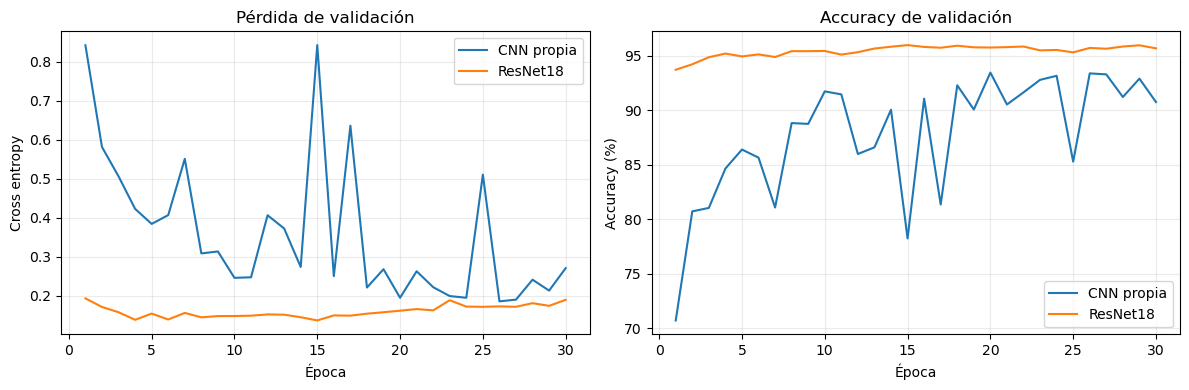

| Época | Accuracy val CNN (%) | Accuracy val ResNet18 (%) |
|---:|---:|---:|
| 1 | 70.72 | 93.70 |
| 2 | 80.72 | 94.20 |
| 3 | 81.04 | 94.85 |
| 4 | 84.65 | 95.19 |
| 5 | 86.39 | 94.93 |
| 6 | 85.65 | 95.11 |
| 7 | 81.07 | 94.87 |
| 8 | 88.81 | 95.41 |
| 9 | 88.74 | 95.41 |
| 10 | 91.72 | 95.43 |
| 11 | 91.44 | 95.09 |
| 12 | 85.98 | 95.31 |
| 13 | 86.59 | 95.65 |
| 14 | 90.04 | 95.81 |
| 15 | 78.24 | 95.96 |
| 16 | 91.06 | 95.80 |
| 17 | 81.35 | 95.72 |
| 18 | 92.28 | 95.91 |
| 19 | 90.06 | 95.76 |
| 20 | 93.44 | 95.74 |
| 21 | 90.52 | 95.78 |
| 22 | 91.63 | 95.83 |
| 23 | 92.78 | 95.48 |
| 24 | 93.15 | 95.52 |
| 25 | 85.28 | 95.30 |
| 26 | 93.37 | 95.70 |
| 27 | 93.28 | 95.63 |
| 28 | 91.20 | 95.83 |
| 29 | 92.89 | 95.94 |
| 30 | 90.74 | 95.67 |


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, historial in [('CNN propia', history_custom), ('ResNet18', history_tl)]:
    epochs_modelo = range(1, len(historial['val_loss']) + 1)
    axes[0].plot(epochs_modelo, historial['val_loss'], label=name)
    axes[1].plot(epochs_modelo, historial['val_acc'], label=name)
axes[0].set_title('Pérdida de validación')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Cross entropy')
axes[1].set_title('Accuracy de validación')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy (%)')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


tabla_epocas = '| Época | Accuracy val CNN (%) | Accuracy val ResNet18 (%) |\n'
tabla_epocas += '|---:|---:|---:|\n'
epocas_comunes = min(len(history_custom['val_acc']), len(history_tl['val_acc']))
for epoch in range(epocas_comunes):
    tabla_epocas += (f'| {epoch + 1} | {history_custom["val_acc"][epoch]:.2f} | '
                     f'{history_tl["val_acc"][epoch]:.2f} |\n')
display(Markdown(tabla_epocas))


### Rendimiento final en test
Los modelos se evalúan con los pesos elegidos por validación. Presentamos las
métricas por clase y una tabla que compara accuracy y tiempo medio por época.

| Clase | Precision | Recall | F1 | Imágenes |
|---|---:|---:|---:|---:|
| AnnualCrop | 0.95 | 0.97 | 0.96 | 300 |
| Forest | 0.98 | 0.99 | 0.99 | 300 |
| HerbaceousVegetation | 0.96 | 0.95 | 0.96 | 300 |
| Highway | 0.94 | 0.89 | 0.91 | 250 |
| Industrial | 0.96 | 0.98 | 0.97 | 250 |
| Pasture | 0.94 | 0.96 | 0.95 | 200 |
| PermanentCrop | 0.95 | 0.93 | 0.94 | 250 |
| Residential | 0.99 | 0.99 | 0.99 | 300 |
| River | 0.93 | 0.96 | 0.94 | 250 |
| SeaLake | 1.00 | 0.99 | 1.00 | 300 |


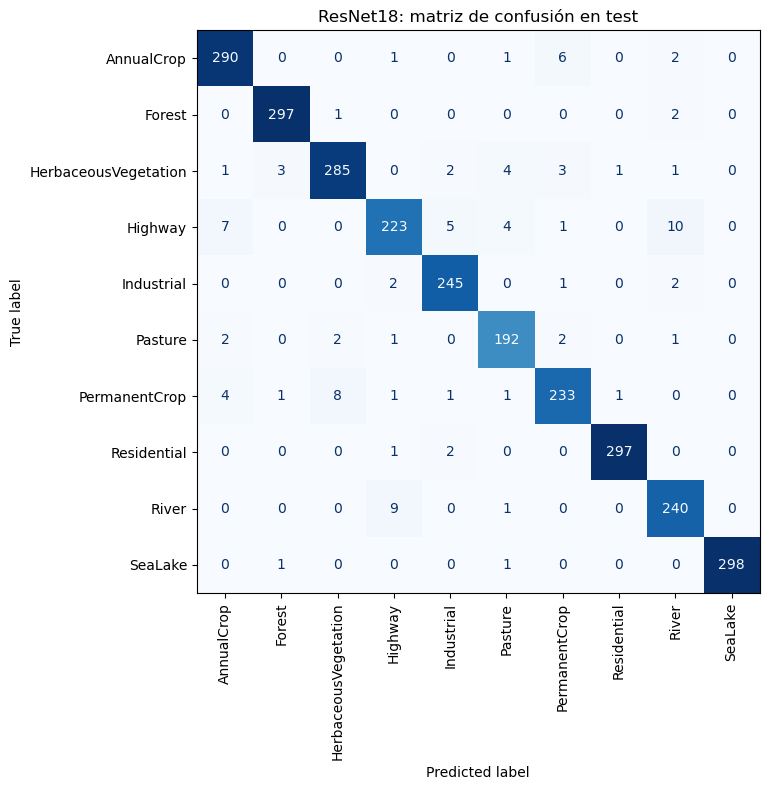

| Modelo | Accuracy test | Mejor época (val loss) | Val accuracy de esa época | Segundos/época |
|---|---:|---:|---:|---:|
| CNN propia | 0.9470 | 26 | 93.37% | 56.09 |
| ResNet18 | 0.9630 | 15 | 95.96% | 143.62 |


In [30]:
y_test_tl, pred_tl = predecir(model_tl, test_loader_tl)
assert np.array_equal(y_test, y_test_tl)
acc_tl = accuracy_score(y_test_tl, pred_tl)
mostrar_metricas(y_test_tl, pred_tl)

cm_tl = confusion_matrix(y_test_tl, pred_tl, labels=range(num_classes))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm_tl, display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False, xticks_rotation=90
)
ax.set_title('ResNet18: matriz de confusión en test')
plt.tight_layout()
plt.show()

tiempo_custom = float(np.mean(history_custom['seconds']))
tiempo_tl = float(np.mean(history_tl['seconds']))
tabla = '| Modelo | Accuracy test | Mejor época (val loss) | Val accuracy de esa época | Segundos/época |\n'
tabla += '|---|---:|---:|---:|---:|\n'
tabla += (f'| CNN propia | {acc_custom:.4f} | {best_epoch_custom} | '
          f'{best_val_acc_custom:.2f}% | {tiempo_custom:.2f} |\n')
tabla += (f'| ResNet18 | {acc_tl:.4f} | {best_epoch_tl} | '
          f'{best_val_acc_tl:.2f}% | {tiempo_tl:.2f} |\n')
display(Markdown(tabla))


## Conclusión

### Análisis de transferencia y conclusión

ResNet18 ajustó 8.398.858 parámetros de layer4 y fc; las capas anteriores
conservaron sus pesos y estadísticas de BatchNorm. En su primera época alcanzó
93.70% en validación, frente al 70,72% inicial de la CNN propia.
En tres épocas llegó a 94.85%, mientras la CNN registró 81,04%.
Esta es una ventaja de convergencia observada con el pipeline acordado, no una
prueba que aísle el efecto del preentrenamiento de la arquitectura.

La época elegida fue la 15, con loss de validación 0.1374
y accuracy 95.96%. Train pasó de 87.96% a 99.14%,
pero la última validación fue 95.67%. Se restauró el estado de menor
pérdida en lugar de usar automáticamente los últimos pesos. Las mejoras de train
no se tradujeron de manera uniforme en menor pérdida de validación.

En test, ResNet18 obtuvo 96,30% de accuracy y la CNN propia 94,70%.
La diferencia descriptiva fue de aproximadamente 1,6 puntos porcentuales.

La mejora se concentra especialmente en HerbaceousVegetation: su recall pasó de
0,86 a 0,95. Sus predicciones erróneas como PermanentCrop bajaron de 24 a 3,
el sentido contrario conservó 8 casos. El par pasó de 32 a 11 errores.
En cambio, Highway redujo su recall de 0,93 a 0,89, y Highway ↔ River aumentó
de 13 a 19 errores. El mejor resultado global no significó una mejora en cada clase.

ResNet18 aprendió más rápido por época, pero cada época fue más
costosa en CPU. 

Ambos enfoques usaron 64 × 64, las mismas particiones, normalización, aumentos,
lotes y 30 épocas, con tasas de aprendizaje fijas. Esta comparación mantiene constante el pipeline, aunque no separa el efecto de arquitectura,
capacidad y entrenamiento. El presupuesto iguala épocas, no tiempo de cómputo.

Test no se utilizó para elegir épocas o tasas. La conclusión se apoya en las
métricas ejecutadas, las matrices de confusión y
el análisis escrito de los errores, con las limitaciones señaladas.

En esta ejecución, ResNet18 obtuvo el mayor accuracy de test, a cambio de un mayor costo por época. La CNN propia fue más económica de entrenar por época y tuvo muchos menos parámetros. El resultado favorece al fine-tuning en métricas bajo este protocolo, sin afirmar que sea superior en cualquier contexto.
